# Step 1:Business Problem Understanding

#### Predict employee salaries based on factors such as age, education, job title, and years of experience. Traditional salary estimation can be inconsistent and time-consuming, so machine learning regression algorithms can help organizations make more consistent, data-driven salary estimates.

### Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Step-2: Data Collection

In [2]:
data = pd.read_csv(r"C:\Users\hp\Downloads\Salary_Data.csv")
data.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [3]:
data.size

40224

In [4]:
data.shape

(6704, 6)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


In [6]:
data.describe()

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


## Step: 3 - Data Cleaning

In [7]:
data.isnull().sum()

Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64

In [8]:
# Remove rows where Salary is missing
data = data.dropna(subset=["Salary"])

# Fill missing numerical values with median
num_cols = ["Age", "Years of Experience"]
data[num_cols] = data[num_cols].fillna(data[num_cols].median())

# Fill missing categorical values with mode
cat_cols = ["Gender", "Education Level", "Job Title"]

for col in cat_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

# Check missing values again
print(data.isnull().sum())

Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64


In [9]:
data.duplicated().sum()

np.int64(4911)

In [10]:
categorical=[]
continous=[]
check=[]
d_types = dict(data.dtypes)
for name , type in d_types.items():
    if str(type) == 'object':
        categorical.append(name)
    elif str(type) =='float64':
        continous.append(name)
    else:
        check.append(name)
print("categorical features:",categorical)
print("continous features:",continous)
print("features to be checked:",check)  

categorical features: ['Gender', 'Education Level', 'Job Title']
continous features: ['Age', 'Years of Experience', 'Salary']
features to be checked: []


In [11]:
d_types = dict(data.dtypes)
for name ,type_ in d_types.items():
    if str(type_)=='object':
        print(f"<==={name}===>")
        print(data[name].value_counts())

<===Gender===>
Gender
Male      3672
Female    3013
Other       14
Name: count, dtype: int64
<===Education Level===>
Education Level
Bachelor's Degree    2266
Master's Degree      1572
PhD                  1368
Bachelor's            756
High School           448
Master's              288
phD                     1
Name: count, dtype: int64
<===Job Title===>
Job Title
Software Engineer                     518
Data Scientist                        453
Software Engineer Manager             376
Data Analyst                          363
Senior Project Engineer               318
                                     ... 
Junior Social Media Specialist          1
Senior Product Development Manager      1
Senior Software Architect               1
Developer                               1
Social Media Man                        1
Name: count, Length: 192, dtype: int64


## Step 4:Exploratory Data Analysis (EDA)

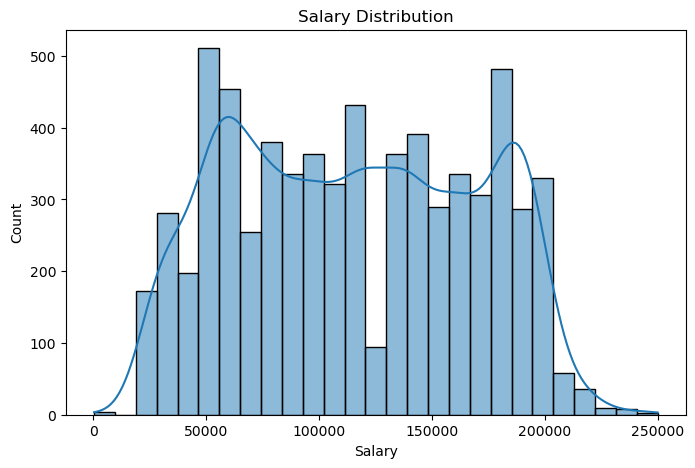

In [12]:
# Salary distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x="Salary", kde=True)
plt.title("Salary Distribution")
plt.show()

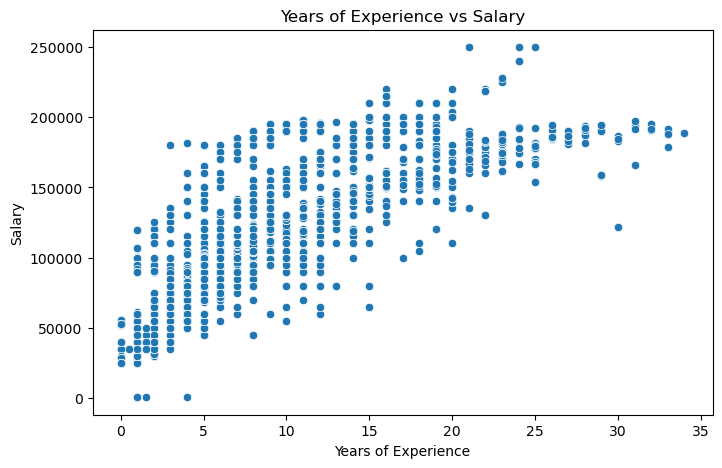

In [13]:
# Experience vs Salary
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data,
    x="Years of Experience",
    y="Salary"
)
plt.title("Years of Experience vs Salary")
plt.show()

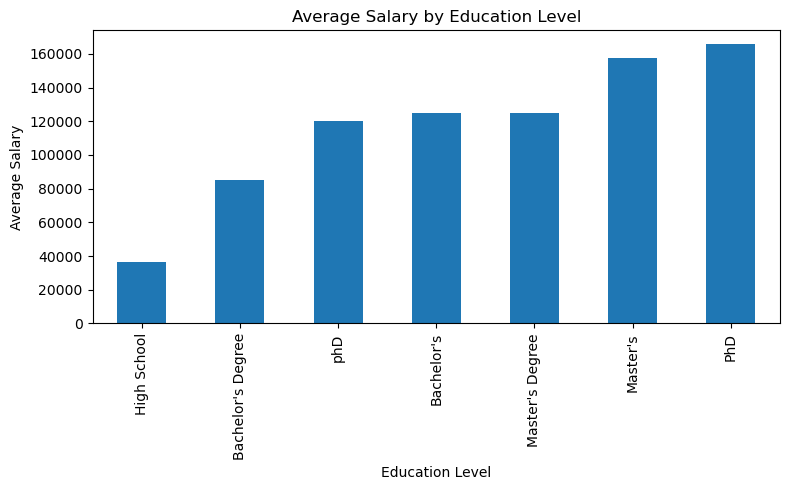

In [14]:
# Average salary by education level
data.groupby("Education Level")["Salary"].mean().sort_values().plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Average Salary by Education Level")
plt.ylabel("Average Salary")
plt.tight_layout()
plt.show()

## Step-5: Data Wrangling

In [15]:
# Features
x = data.drop("Salary", axis=1)

# Target
y = data["Salary"]

print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (6699, 5)
Target shape: (6699,)


### Encoding

In [16]:

from sklearn.preprocessing import LabelEncoder
import joblib

# Categorical columns
cat_cols = ["Gender", "Education Level", "Job Title"]

# Store a separate encoder for each column
encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col].astype(str))
    encoders[col] = le

# Save encoders for future predictions
joblib.dump(encoders, "salary_encoders.pkl")

# Display encoded dataset
print(data.head())

# Check data types
print(data.dtypes)

print("Encoders saved successfully!")


    Age  Gender  Education Level  Job Title  Years of Experience    Salary
0  32.0       1                0        176                  5.0   90000.0
1  28.0       0                3         18                  3.0   65000.0
2  45.0       1                5        145                 15.0  150000.0
3  36.0       0                0        116                  7.0   60000.0
4  52.0       1                3         26                 20.0  200000.0
Age                    float64
Gender                   int64
Education Level          int64
Job Title                int64
Years of Experience    float64
Salary                 float64
dtype: object
Encoders saved successfully!


In [17]:
print(data.isnull().sum())

Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64


## Step- 6: Train-Test Split

In [18]:

from sklearn.model_selection import train_test_split

# Separate input features and target variable
x = data.drop("Salary", axis=1)
y = data["Salary"]

# Split the dataset
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

# Display shapes
print("X_train:", x_train.shape)
print("X_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (5359, 5)
X_test: (1340, 5)
y_train: (5359,)
y_test: (1340,)


## Step-7: Feature Scaling

In [19]:

from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit on training data and transform it
x_train_scaled = scaler.fit_transform(x_train)

# Transform testing data using the same scaler
x_test_scaled = scaler.transform(x_test)

print("Training data shape:", x_train_scaled.shape)
print("Testing data shape:", x_test_scaled.shape)

print("Feature scaling completed!")


Training data shape: (5359, 5)
Testing data shape: (1340, 5)
Feature scaling completed!


## Step-8 :Model Training

## Model 1: Linear Regression

In [20]:
 #import
from sklearn.linear_model import LinearRegression
model = LinearRegression()

# fit 
model.fit(x_train, y_train)


LinearRegression()

In [21]:
a=model.intercept_
b=model.coef_
print(a)
print(b)

98150.87470414251
[-1772.35252904  5556.77356575  2123.95689988   -28.76712996
  8780.72523913]


## Step -9 :Predicting

In [22]:
#Predictions
train_predictions = model.predict(x_train)
test_predictions= model.predict(x_test)

## Step -10 : Evaluation

In [23]:
from sklearn.metrics import mean_absolute_error
print("Mean absolute error for test data:",mean_absolute_error(y_test,test_predictions))
print("Mean absolute error for train data:",mean_absolute_error(y_train ,train_predictions))

Mean absolute error for test data: 23673.555518203102
Mean absolute error for train data: 24271.905956731895


In [24]:
from sklearn.metrics import mean_squared_error
print("Mean square error for test data:",mean_squared_error(y_test,test_predictions))
print("Mean square error for train data:",mean_squared_error(y_train ,train_predictions))

Mean square error for test data: 885268733.6970595
Mean square error for train data: 928855615.5964884


In [25]:
print("RMSE for the test data:",np.sqrt(mean_squared_error(y_test,test_predictions)))
print("RMSE for the train data:", np.sqrt(mean_squared_error(y_train,train_predictions)))

RMSE for the test data: 29753.465910664247
RMSE for the train data: 30477.132666910915


In [26]:
from sklearn.metrics import r2_score  #best fit
print("R2 for test data:",r2_score(y_test,test_predictions))
print("R2 for train data:",r2_score(y_train,train_predictions))

R2 for test data: 0.6886100246201177
R2 for train data: 0.6648714632263049


#### 1.Is model has Underfitting or overfitting Problem?
Good fit

#### 2 .Is TestScore = Cross Validation Score

In [27]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model,
    x_train,
    y_train,
    cv=5,
    scoring="r2")
print(scores)
cv_score=scores.mean()
print("CrossValidation Score :",cv_score)

[0.63431635 0.69317728 0.65919343 0.68014018 0.65299604]
CrossValidation Score : 0.66396465653335


####  TestScore != Cross Validation Score

## Model 2: Decision Tree Regressor 

In [28]:
# Import
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(random_state=42)

# Fit
model.fit(x_train, y_train)

DecisionTreeRegressor(random_state=42)

In [29]:
# Training score
train_score = model.score(x_train, y_train)

# Testing score
test_score = model.score(x_test, y_test)

print("Training Score:", train_score)
print("Testing Score:", test_score)

Training Score: 0.9968206809338097
Testing Score: 0.9623461101447687


#### 1.Is model has Underfitting or overfitting Problem?
Good fit

#### 2 .Is TestScore = Cross Validation Score

In [30]:
# Import
from sklearn.model_selection import cross_val_score

# Cross-validation
scores = cross_val_score(
    model,
    x_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("Cross-validation scores:", scores)
print("Cross-validation Score:", scores.mean())

Cross-validation scores: [0.94923132 0.97435542 0.97228553 0.95852841 0.97747149]
Cross-validation Score: 0.9663744347226728


####  TestScore != Cross Validation Score

## Model 3: Random Forest Regressor

In [31]:
# Import
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Fit
rf_model.fit(x_train, y_train)




RandomForestRegressor(random_state=42)

In [32]:
# Training score
train_score = rf_model.score(x_train, y_train)

# Testing score
test_score = rf_model.score(x_test, y_test)

print("Training Score:", train_score)
print("Testing Score:", test_score)

Training Score: 0.9940995230440605
Testing Score: 0.976469782162976


#### 1.Is model has Underfitting or overfitting Problem?
Good fit

#### 2 .Is TestScore = Cross Validation Score

In [33]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Use 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_r = cross_val_score(
    rf_model,
    x_train,
    y_train,
    cv=kf,
    scoring="r2"
)

print("Individual CV Scores:", cv_scores_r)
print("Mean Cross-Validation Score:", cv_scores_r.mean())
print("Mean CV Score (%):", round(cv_scores_r.mean() * 100, 2))


Individual CV Scores: [0.9710301  0.97620583 0.97814757 0.97142167 0.973517  ]
Mean Cross-Validation Score: 0.9740644325059072
Mean CV Score (%): 97.41


####  TestScore == Cross Validation Score

## Model: 4-Support Vector Regression (SVR)

In [34]:
# Import
from sklearn.svm import SVR

model = SVR(kernel="rbf")

# Fit
model.fit(x_train_scaled, y_train)


SVR()

In [35]:
# Training score
train_score = model.score(x_train_scaled, y_train)

# Testing score
test_score = model.score(x_test_scaled, y_test)

print("Training Score:", train_score)
print("Testing Score:", test_score)

Training Score: 0.014509377307521332
Testing Score: 0.0146431626366339


#### 1.Is model has Underfitting or overfitting Problem?
Good fit

#### 2 .Is TestScore = Cross Validation Score

In [36]:
# Import
from sklearn.model_selection import cross_val_score

# Cross-validation
scores = cross_val_score(
    model,
    x_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("Cross-validation scores:", scores)
print("Cross-validation Score:", scores.mean())

Cross-validation scores: [0.00013391 0.00200696 0.00208542 0.00197992 0.00054173]
Cross-validation Score: 0.0013495874486212588


####  TestScore != Cross Validation Score

## Model 5: AdaBoost Regressor

In [37]:
# Import
from sklearn.ensemble import AdaBoostRegressor

model = AdaBoostRegressor(
    n_estimators=100,
    random_state=42
)

# Fit
model.fit(x_train, y_train)

AdaBoostRegressor(n_estimators=100, random_state=42)

In [38]:

# Training score
train_score = model.score(x_train, y_train)

# Testing score
test_score = model.score(x_test, y_test)

print("Training Score:", train_score)
print("Testing Score:", test_score)

Training Score: 0.8012836523335081
Testing Score: 0.8066921610298825


#### 1.Is model has Underfitting or overfitting Problem?
Good fit

#### 2 .Is TestScore = Cross Validation Score

In [39]:
# Import
from sklearn.model_selection import cross_val_score

# Cross-validation
scores = cross_val_score(
   model,
    x_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("Cross-validation scores:", scores)
print("Cross-validation Score:", scores.mean())

Cross-validation scores: [0.78654777 0.79256346 0.81097516 0.79937131 0.78999374]
Cross-validation Score: 0.7958902897800069


####  TestScore = Cross Validation Score

## Model 6 : KNN Regressor

In [40]:
# Import
from sklearn.neighbors import KNeighborsRegressor

knn_model = KNeighborsRegressor(n_neighbors=5)

# Fit
knn_model.fit(x_train_scaled, y_train)

KNeighborsRegressor()

In [41]:
# Training score
train_score = knn_model.score(x_train_scaled, y_train)

# Testing score
test_score = knn_model.score(x_test_scaled, y_test)

print("Training Score:", train_score)
print("Testing Score:", test_score)

Training Score: 0.9728662373803302
Testing Score: 0.9550582783713842


#### 1.Is model has Underfitting or overfitting Problem?
Good fit

#### 2 .Is TestScore = Cross Validation Score

In [42]:
# Import
from sklearn.model_selection import cross_val_score

# Cross-validation
scores = cross_val_score(
    knn_model, x_train_scaled, y_train, cv=5, scoring="r2"
)

print("Cross-validation scores:", scores)
print("Cross-validation Score:", scores.mean())

Cross-validation scores: [0.92280595 0.95829176 0.95773673 0.9474372  0.96566241]
Cross-validation Score: 0.950386812133537


#### 2 .Is TestScore = Cross Validation Score
yes

## Model-7: XGBoost Regressor

In [43]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [44]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    objective="reg:squarederror"
)

xgb_model.fit(x_train, y_train)

print("XGBoost model trained successfully!")
print("Training R² Score:", xgb_model.score(x_train, y_train))
print("Testing R² Score:", xgb_model.score(x_test, y_test))

XGBoost model trained successfully!
Training R² Score: 0.9610811082446366
Testing R² Score: 0.9545632798997258


#### 1.Is model has Underfitting or overfitting Problem?
Good fit

#### 2 .Is TestScore = Cross Validation Score


In [45]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Cross-validation on training data
cv_scores = cross_val_score(
    xgb_model,
    x_train,
    y_train,
    cv=5,
    scoring="r2"
)

# Predictions on test data
y_pred = xgb_model.predict(x_test)

# Error metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Cross Validation Score:", cv_scores.mean())
print("Individual CV Scores:", cv_scores)
print("MAE:", mae)
print("RMSE:", rmse)

Cross Validation Score: 0.9516343860056182
Individual CV Scores: [0.94174056 0.95317336 0.95593385 0.95275241 0.95457176]
MAE: 7799.057897038247
RMSE: 11365.504971437427


#### 2 .Is TestScore = Cross Validation Score
yes

## 1.Model comparison

#### Step 1: Create the comparison table

In [46]:
import pandas as pd

results = {
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "KNN Regressor",
        "SVR",
        "AdaBoost Regressor",
        "XGBoost Regressor"
    ],
    "Training Score": [
        0.664871, 0.996821, 0.994100,
        0.972866, 0.014509, 0.801284, 0.96108
    ],
    "Testing Score": [
        0.688610, 0.962346, 0.976470,
        0.955058, 0.014643, 0.806692,0.95456
    ],
    "Cross-Validation Score": [
        0.386220, 0.966374,0.974130,
        0.950387, 0.010679, 0.573837, 0.951634
    ]
}

comparison_df = pd.DataFrame(results)

print(comparison_df.round(4))

                Model  Training Score  Testing Score  Cross-Validation Score
0   Linear Regression          0.6649         0.6886                  0.3862
1       Decision Tree          0.9968         0.9623                  0.9664
2       Random Forest          0.9941         0.9765                  0.9741
3       KNN Regressor          0.9729         0.9551                  0.9504
4                 SVR          0.0145         0.0146                  0.0107
5  AdaBoost Regressor          0.8013         0.8067                  0.5738
6   XGBoost Regressor          0.9611         0.9546                  0.9516


#### Step 2: Display the table as percentages

In [47]:
score_columns = [
    "Training Score",
    "Testing Score",
    "Cross-Validation Score"
]

comparison_df[score_columns] = (
    comparison_df[score_columns] * 100
)

print(comparison_df.round(2).to_string(index=False))

             Model  Training Score  Testing Score  Cross-Validation Score
 Linear Regression           66.49          68.86                   38.62
     Decision Tree           99.68          96.23                   96.64
     Random Forest           99.41          97.65                   97.41
     KNN Regressor           97.29          95.51                   95.04
               SVR            1.45           1.46                    1.07
AdaBoost Regressor           80.13          80.67                   57.38
 XGBoost Regressor           96.11          95.46                   95.16


## 2. Which model is best?

###  Random Forest:
Highest CV score at 97.41%, with a testing score of 97.65%.

### XGBoost: 
Highest CV score at 95.16%, with a testing score of 95.46%.

### KNN: 
CV score of 95.04% and testing score of 95.51%. Its results are also consistent.


#### Plot the model comparison

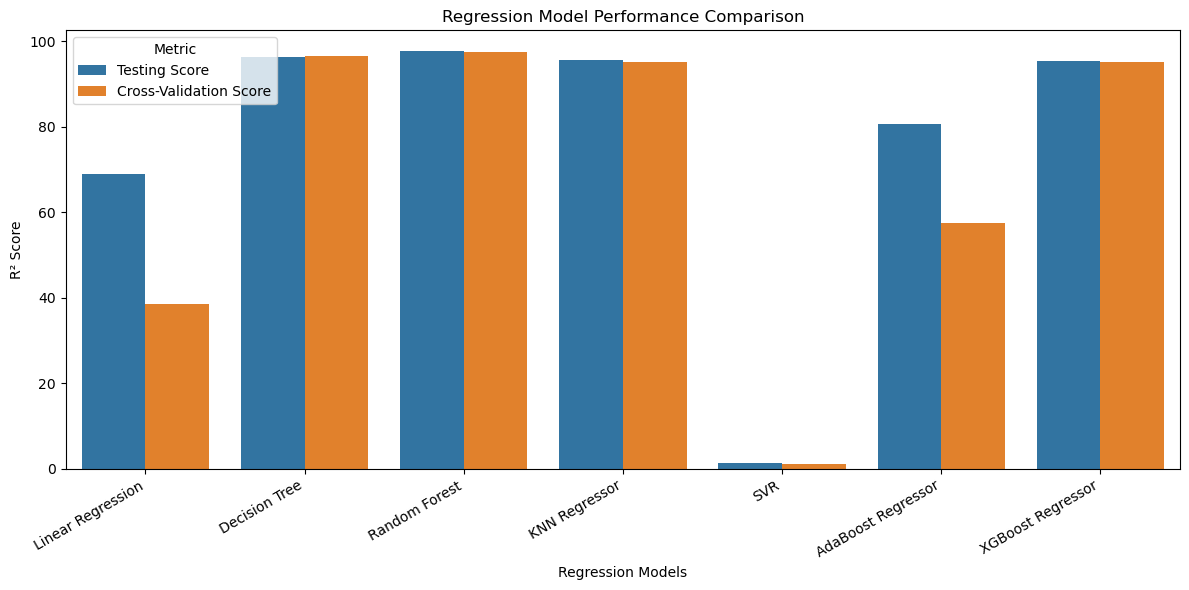

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot Testing and Cross-Validation Scores
comparison_plot = comparison_df.melt(
    id_vars="Model",
    value_vars=["Testing Score", "Cross-Validation Score"],
    var_name="Metric",
    value_name="R2 Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_plot,
    x="Model",
    y="R2 Score",
    hue="Metric"
)

plt.title("Regression Model Performance Comparison")
plt.ylabel("R² Score")
plt.xlabel("Regression Models")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Model Selection

#### RandomForest Regressor
After evaluating seven regression algorithms, RandomForest Regressor was selected as the preferred model because it achieved a testing R² score of 97.65 % and the highest cross-validation score of 97.41 %. These results indicate consistent predictive performance for the Employee Salary Prediction project.

## Load the model

In [49]:
from joblib import load

load_model = load("salary_model.joblib")

## Save and load the scaler and encoders too

In [50]:
from joblib import dump, load

# Save
dump(rf_model, "salary_model.joblib")
dump(scaler, "salary_scaler.joblib")
dump(encoders, "salary_encoders.joblib")

# Load
load_model = load("salary_model.joblib")
loaded_scaler = load("salary_scaler.joblib")
loaded_encoders = load("salary_encoders.joblib")

print("Model, scaler, and encoders loaded successfully!")

Model, scaler, and encoders loaded successfully!


## Predict an employee's salary

In [51]:
%pip install ipywidgets

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [52]:

import pandas as pd
import joblib
import ipywidgets as widgets
from IPython.display import display, clear_output

# Load saved files
loaded_model = joblib.load("salary_prediction_model.pkl")
loaded_scaler = joblib.load("salary_scaler.pkl")
encoders = joblib.load("salary_encoders.pkl")

# Input fields
age_input = widgets.IntText(
    value=25, description="Age:"
)

gender_input = widgets.Dropdown(
    options=encoders["Gender"].classes_.tolist(),
    description="Gender:"
)

education_input = widgets.Dropdown(
    options=encoders["Education Level"].classes_.tolist(),
    description="Education:"
)

job_input = widgets.Dropdown(
    options=encoders["Job Title"].classes_.tolist(),
    description="Job Title:"
)

experience_input = widgets.FloatText(
    value=0.0, description="Experience:"
)

predict_button = widgets.Button(
    description="Predict Salary",
    button_style="success",
    icon="calculator"
)

output = widgets.Output()

def predict_salary(b):
    with output:
        clear_output()

        try:
            # Encode categorical inputs
            gender_encoded = encoders["Gender"].transform(
                [gender_input.value]
            )[0]

            education_encoded = encoders["Education Level"].transform(
                [education_input.value]
            )[0]

            job_encoded = encoders["Job Title"].transform(
                [job_input.value]
            )[0]

            # Prepare features in training order
            new_employee = pd.DataFrame([{
                "Age": age_input.value,
                "Gender": gender_encoded,
                "Education Level": education_encoded,
                "Job Title": job_encoded,
                "Years of Experience": experience_input.value
            }], columns=[
                "Age",
                "Gender",
                "Education Level",
                "Job Title",
                "Years of Experience"
            ])

            # Scale and predict
            employee_scaled = loaded_scaler.transform(new_employee)
            prediction = loaded_model.predict(employee_scaled)[0]

            print(f"Predicted Salary: {prediction:,.2f}")

        except Exception as e:
            print("Prediction error:", e)

predict_button.on_click(predict_salary)

# Display the interface
display(
    age_input,
    gender_input,
    education_input,
    job_input,
    experience_input,
    predict_button,
    output
)


IntText(value=25, description='Age:')

Dropdown(description='Gender:', options=('Female', 'Male', 'Other'), value='Female')

Dropdown(description='Education:', options=("Bachelor's", "Bachelor's Degree", 'High School', "Master's", "Mas…

Dropdown(description='Job Title:', options=('Account Manager', 'Accountant', 'Administrative Assistant', 'Back…

FloatText(value=0.0, description='Experience:')

Button(button_style='success', description='Predict Salary', icon='calculator', style=ButtonStyle())

Output()